# Option-Adjusted Spreads for Agency Mortgage Pools: a Hull–White Model Calibrated to Today's Treasury Curve and the MOVE Index, Three Prepayment Functions from 2.9 Million Freddie Mac Loan-Months, Effective Duration and Negative Convexity

An agency mortgage pool pays its investors the interest and principal of thousands of fixed-rate mortgages, with the credit risk guaranteed by Freddie Mac, Fannie Mae or Ginnie Mae. What is left is interest-rate risk with a twist: every borrower holds an option to repay at par. When rates fall, borrowers refinance and the investor gets cash back just when it can only be reinvested at lower rates; when rates rise, nobody refinances and the pool's life extends just when its cash would be worth more elsewhere. The option-adjusted spread (OAS) is the spread over the Treasury curve that, averaged over many interest-rate paths, discounts the pool's projected cash flows to its price. It needs three ingredients: a term-structure model calibrated to today's market, a prepayment function that turns each rate path into cash flows, and a price.

This notebook builds all three from public data. A one-factor Hull–White model is fitted exactly to today's Treasury curve and given the volatility implied by the MOVE index. Three prepayment functions are estimated on monthly loan-level histories of Freddie Mac mortgages originated in 2018–2023, through the 2020–2021 refinancing wave and the 2022–2023 lock-in: an industry-style parametric S-curve, a spline logistic regression and LightGBM, each tested out of time. The pools are the loans of the sample still outstanding at the end of the data, grouped by coupon, and priced with each prepayment model.

**What it does.**

1. It reads the monthly payment histories of 72,000 loans, labels each month in which a loan was repaid in full, and computes each loan's refinancing incentive (note rate minus the prevailing mortgage rate), its burnout (accumulated past incentive it did not use), age, season and borrower characteristics.
2. It fits the three prepayment functions on 2018–2023 and tests them on 2024–2026: log loss, discrimination, the S-curve of prepayment speed against incentive, and the tracking of the monthly prepayment rate of the whole sample.
3. It builds the Treasury zero curve from today's constant-maturity yields, calibrates Hull–White's volatility to the MOVE index, simulates 1,000 monthly rate paths over 30 years, and maps the 10-year yield on each path into a mortgage rate.
4. It groups outstanding loans into pools by coupon, projects their cash flows on every path with each prepayment model, fixes the OAS by pricing a newly produced current-coupon pool at par, and computes, for each pool, the price at that OAS, the static (zero-volatility) spread, the option cost, effective duration and effective convexity.
5. It shows the price profile under parallel rate shifts, the sensitivity of OAS and duration to the volatility and mean-reversion assumptions and to the prepayment model, and compares the model durations with the empirical duration of the largest mortgage-backed securities ETF.

**Data.** Freddie Mac Single-Family Loan-Level Dataset, sample files 2018–2023 (free registration; downloaded once by hand into `data/freddie_mac/` at the repository root); Treasury constant-maturity yields and the 30-year mortgage rate (FRED); the MOVE index and the MBB and IEF ETFs (Yahoo Finance).

**Methods.** Hull–White one-factor model fitted to the initial curve, volatility calibration to the MOVE index, Monte Carlo with antithetic paths and moment matching, prepayment hazard models (parametric S-curve by maximum likelihood, spline logistic regression, LightGBM with monotonic constraints), out-of-time validation, option-adjusted and zero-volatility spreads, effective duration and convexity, rolling empirical duration.

**Key output.** Out-of-time accuracy of the three prepayment functions and their S-curves; the Hull–White calibration; for each coupon pool, the price, OAS, option cost, effective duration and convexity; price profiles under rate shocks; and how much OAS and duration depend on the volatility and prepayment assumptions.

## 1. OAS in one page

**Cash flows of a pool.** Each month a mortgage with balance *B*, note rate *r* and *n* months left pays the level payment *B i* / (1 − (1 + *i*)<sup>−*n*</sup>), *i* = *r* / 12. The investor receives interest at the pool coupon *c* (the note rate minus servicing and guarantee fees), the scheduled principal, and the prepayments: a fraction SMM (single monthly mortality) of the balance left after scheduled principal. Prepayment speeds are quoted as annualised CPR = 1 − (1 − SMM)<sup>12</sup>.

**Prepayment.** Borrowers repay in full when they sell the house (turnover, a few percent a year, more for newer loans and in summer) or refinance (when the market rate falls well below their note rate). Plotted against the incentive, speeds trace an S-curve: flat when out of the money, steep around 0.5–1.5 percentage points of incentive, saturating above. Borrowers who stayed through earlier incentives are less responsive (burnout), and borrowers far out of the money move less (lock-in).

**Rate model.** Hull–White's short rate *dr* = (θ(*t*) − *a r*) *dt* + σ *dW* fits any initial curve exactly through θ(*t*), and gives bond prices in closed form, so the 10-year Treasury yield, and hence the mortgage rate, is known at every point of every simulated path.

**OAS.** With discount factors *D*<sub>*p*,*k*</sub> along path *p* and projected cash flows CF<sub>*p*,*k*</sub>, the OAS is the spread *s* such that

Price = (1/*N*) Σ<sub>*p*</sub> Σ<sub>*k*</sub> CF<sub>*p*,*k*</sub> *D*<sub>*p*,*k*</sub> e<sup>−*s t*<sub>*k*</sub></sup>.

The **zero-volatility spread** does the same on the single path of forward rates. The difference, the **option cost**, is what the borrowers' option takes from the investor. **Effective duration and convexity** reprice the pool at a fixed OAS after shifting the curve up and down: unlike a bond, a mortgage pool's price rises less when rates fall than it falls when rates rise (negative convexity).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile

import lightgbm as lgb
import yfinance as yf
from scipy.optimize import brentq, minimize
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 1986
rng = np.random.default_rng(SEED)
VINTAGES, LOANS_PER_VINTAGE = [2018, 2019, 2020, 2021, 2022, 2023], 12_000
# out-of-time test period starts here
OOT_START = pd.Timestamp("2024-01-01")
# note rate minus pool coupon floor (servicing + guarantee fee), %
FEE = 0.50
# Hull-White mean reversion (per year)
HW_A = 0.03
# simulated paths (antithetic pairs), horizon in months
N_PATHS, MONTHS, DT = 1_000, 360, 1 / 12
# parallel shift for effective duration, percentage points
SHOCK = 0.25
# loan age enters the models capped at 6 years (the sample has no older loans)
AGE_CAP = 72
MOVE_WEIGHTS = {2: 0.2, 5: 0.2, 10: 0.4, 30: 0.2}
TENORS = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Loan-months, prepayments and the refinancing incentive

For each vintage the notebook draws 12,000 thirty-year fixed-rate loans at random and reads their monthly records. A month counts as a **prepayment** when the loan is repaid in full (zero-balance code 01); loans that leave through a credit event are censored at that point, because in an agency pool the guarantor buys them out at par and the investor sees a prepayment that has nothing to do with rates. Months that start 60 days or more past due are dropped. Partial prepayments (curtailments) are not modelled. The oldest loans in the sample are eight years old, so loan age enters every model capped at six years: speeds of older loans are assumed to stay at the level of fully seasoned ones rather than extrapolated from a handful of survivors.

The **incentive** is the loan's current note rate minus Freddie Mac's 30-year mortgage rate of the previous month (refinancing takes a few weeks to close). **Burnout** adds up the positive incentive of all earlier months: a borrower who has been in the money for a year without refinancing is less likely to do so now. The spread at origination (note rate minus the market rate when the loan was made) captures borrowers who paid above the market, typically weaker credits.

In [3]:
OC = [
    "fico",
    "first_pay",
    "fthb",
    "maturity",
    "msa",
    "mi_pct",
    "units",
    "occupancy",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "channel",
    "ppm",
    "amort",
    "state",
    "prop_type",
    "zip",
    "loan_id",
    "purpose",
    "term",
    "n_borrowers",
]
PERF = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dlq",
    4: "age",
    8: "zb",
    10: "cur_rate",
}


def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


def vintage_zip(year):
    base = find_shared("freddie_mac")
    hits = (
        [
            h
            for h in base.rglob(f"sample_{year}.zip")
            if "_to_delete" not in h.parts
        ]
        if base
        else []
    )
    if not hits:
        raise FileNotFoundError(
            f"sample_{year}.zip not found under data/freddie_mac/ (see the"
            " README)"
        )
    return min(hits, key=lambda h: len(h.parts))


def load_orig():
    out = []
    for y in VINTAGES:
        with zipfile.ZipFile(vintage_zip(y)) as z:
            o = pd.read_csv(
                z.open(f"sample_orig_{y}.txt"),
                sep="|",
                header=None,
                usecols=range(len(OC)),
                names=OC,
                dtype=str,
            )
        o = o[(o["amort"] == "FRM") & (o["term"] == "360")]
        out.append(
            o.sample(
                min(LOANS_PER_VINTAGE, len(o)), random_state=SEED + y
            ).assign(vintage=y)
        )
    return pd.concat(out, ignore_index=True)


def load_perf():
    ids = set(load_orig()["loan_id"])
    out = []
    for y in VINTAGES:
        with zipfile.ZipFile(vintage_zip(y)) as z:
            for ch in pd.read_csv(
                z.open(f"sample_perf_{y}.txt"),
                sep="|",
                header=None,
                usecols=list(PERF),
                names=list(PERF.values()),
                dtype=str,
                chunksize=2_000_000,
            ):
                out.append(ch[ch["loan_id"].isin(ids)])
    return pd.concat(out, ignore_index=True)


O = cached("freddie_prepay_orig", load_orig, max_age_hours=24 * 90)
P = cached("freddie_prepay_perf", load_perf, max_age_hours=24 * 90)

MR = cached(
    "fred_mortgage30",
    lambda: fred.get_series("MORTGAGE30US", observation_start="1990-01-01")
    .rename("rate")
    .to_frame(),
    max_age_hours=24,
)["rate"]
MR.index = pd.to_datetime(MR.index)
MR_M = MR.resample("MS").mean()
MR_LAG = MR_M.shift(1)

for c in ["fico", "cltv", "dti", "upb", "ltv", "rate", "n_borrowers"]:
    O[c] = pd.to_numeric(O[c], errors="coerce")
O.loc[~O["fico"].between(300, 850), "fico"] = np.nan
O.loc[~O["ltv"].between(1, 200), "ltv"] = np.nan
O.loc[~O["dti"].between(0, 65), "dti"] = np.nan
O["orig_month"] = pd.to_datetime(
    O["first_pay"], format="%Y%m"
) - pd.DateOffset(months=2)
O["sato"] = O["rate"] - O["orig_month"].map(MR_M)
O["log_orig_upb"] = np.log(O["upb"])
O["refi"] = O["purpose"].eq("N").astype(float)
O["cash_out"] = O["purpose"].eq("C").astype(float)
O["investor_or_second"] = O["occupancy"].isin(["I", "S"]).astype(float)
O["first_time_buyer"] = O["fthb"].eq("Y").astype(float)
STATIC = [
    "sato",
    "fico",
    "ltv",
    "dti",
    "log_orig_upb",
    "n_borrowers",
    "refi",
    "cash_out",
    "investor_or_second",
    "first_time_buyer",
]

P["period"] = pd.to_datetime(P["period"], format="%Y%m")
P["upb"] = pd.to_numeric(P["upb"], errors="coerce")
P["age"] = pd.to_numeric(P["age"], errors="coerce")
P["cur_rate"] = pd.to_numeric(P["cur_rate"], errors="coerce")
P["dlq"] = pd.to_numeric(
    P["dlq"].replace({"RA": "99"}), errors="coerce"
).fillna(0)
P = P.sort_values(["loan_id", "period"]).reset_index(drop=True)
LAST_PERIOD = P["period"].max()

g = P.groupby("loan_id", sort=False)
P["incentive"] = P["cur_rate"] - P["period"].map(MR_LAG)
pos = P["incentive"].clip(lower=0)
P["burnout"] = pos.groupby(P["loan_id"], sort=False).cumsum() - pos
P["start_dlq"] = g["dlq"].shift(1).fillna(0)
P["start_upb"] = g["upb"].shift(1)
P["prepaid"] = P["zb"].eq("01").astype(np.int8)
P["month_of_year"] = P["period"].dt.month

D = P[
    (P["zb"].isna() | P["zb"].eq("01"))
    & (P["start_dlq"] <= 1)
    & P["incentive"].notna()
].merge(
    O[["loan_id", "vintage", "upb", *STATIC]].rename(
        columns={"upb": "orig_upb"}
    ),
    on="loan_id",
)
D["start_upb"] = D["start_upb"].where(D["start_upb"] > 0, D["orig_upb"])
D["age"] = D["age"].clip(upper=AGE_CAP)
FEATS = ["incentive", "burnout", "age", "month_of_year", *STATIC]

print(
    f"{len(O):,} loans · {len(D):,} loan-months · {D['prepaid'].sum():,} full"
    f" prepayments · {D['period'].min():%Y-%m} to {LAST_PERIOD:%Y-%m}"
)
SUMMARY = D.groupby("vintage").agg(
    loans=("loan_id", "nunique"),
    loan_months=("prepaid", "size"),
    prepayments=("prepaid", "sum"),
    mean_note_rate=("incentive", lambda s: np.nan),
)
SUMMARY["mean_note_rate"] = O.groupby("vintage")["rate"].mean()
SUMMARY["share prepaid by end of data"] = (
    D.groupby("vintage")["prepaid"].sum() / O.groupby("vintage").size()
)
SUMMARY.style.format({
    "loans": "{:,.0f}",
    "loan_months": "{:,.0f}",
    "prepayments": "{:,.0f}",
    "mean_note_rate": "{:.2f}%",
    "share prepaid by end of data": "{:.1%}",
})

72,000 loans · 2,941,253 loan-months · 30,560 full prepayments · 2018-01 to 2026-03


,loans,loan_months,prepayments,mean_note_rate,share prepaid by end of data
vintage,,,,,
2018,"12,000","469,180","9,567",4.82%,79.7%
2019,"12,000","444,097","8,602",4.34%,71.7%
2020,"12,000","596,477","4,658",3.30%,38.8%
2021,"12,000","604,524","2,256",3.10%,18.8%
2022,"12,000","480,496","2,332",5.25%,19.4%
2023,"12,000","346,479","3,145",6.78%,26.2%


## 4. Three prepayment functions, tested out of time

All three models predict the probability that a loan prepays in full in a given month (the SMM of that loan).

- **Parametric S-curve.** The industry-style decomposition, fitted by maximum likelihood: a seasoning ramp times a seasonal factor times the sum of turnover (damped when the loan is out of the money, the lock-in effect) and a logistic refinancing curve in the incentive, decaying with burnout. Nine parameters, each with a reading.
- **Spline logistic regression.** A logistic hazard with cubic splines in incentive, age and burnout, month dummies and linear borrower characteristics.
- **LightGBM.** Gradient-boosted trees on the same features, constrained to be increasing in the incentive and decreasing in burnout so that simulated rate paths cannot produce perverse speeds.

The models are trained on loan-months before 2024 and tested on 2024 to the end of the data. Accuracy is reported for single loans (log loss, AUC) and for what matters for pricing: the balance-weighted prepayment speed of the whole sample, month by month and by incentive bucket.

In [4]:
def s_curve_cpr(th, X):
    inc, burn, age, mon = (
        np.asarray(X[c], float)
        for c in ["incentive", "burnout", "age", "month_of_year"]
    )
    ramp = np.minimum(np.maximum(age, 1) / np.exp(th[5]), 1.0)
    season = 1 + np.tanh(th[6]) * np.cos(2 * np.pi * (mon - th[7]) / 12)
    turnover = np.exp(th[0]) * np.exp(np.exp(th[8]) * np.minimum(inc, 0))
    refi = (
        np.exp(th[1])
        / (1 + np.exp(-(inc - th[2]) / np.exp(th[3])))
        * np.exp(-np.exp(th[4]) * burn / 100)
    )
    return np.clip(ramp * season * (turnover + refi), 1e-6, 0.95)


def s_curve_smm(th, X):
    return 1 - (1 - s_curve_cpr(th, X)) ** (1 / 12)


def fit_s_curve(df):
    y = df["prepaid"].to_numpy()

    def nll(th):
        p = np.clip(s_curve_smm(th, df), 1e-7, 1 - 1e-7)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    th0 = np.array([
        np.log(0.06),
        np.log(0.5),
        0.75,
        np.log(0.3),
        np.log(0.5),
        np.log(30),
        0.15,
        6.0,
        np.log(0.3),
    ])
    return minimize(nll, th0, method="L-BFGS-B", options={"maxiter": 400}).x


def make_glm():
    pre = ColumnTransformer([
        ("inc", SplineTransformer(n_knots=8, degree=3), ["incentive"]),
        (
            "age",
            SplineTransformer(n_knots=6, degree=3, knots="quantile"),
            ["age"],
        ),
        (
            "burn",
            SplineTransformer(n_knots=4, degree=3, knots="quantile"),
            ["burnout"],
        ),
        (
            "mon",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            ["month_of_year"],
        ),
        ("lin", StandardScaler(), STATIC),
    ])
    return make_pipeline(pre, LogisticRegression(C=1.0, max_iter=400))


MONO = [1 if f == "incentive" else -1 if f == "burnout" else 0 for f in FEATS]
LGB_PARAMS = dict(
    objective="binary",
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=500,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.9,
    monotone_constraints=MONO,
    monotone_constraints_method="advanced",
    verbose=-1,
    n_jobs=2,
    seed=SEED,
)


class Prepay:
    """
    Fits the three prepayment functions on a frame of loan-months and predicts
    monthly SMMs.
    """

    def __init__(self, df, n_rounds=None, max_rows=1_500_000):
        fit = df.sample(min(len(df), max_rows), random_state=SEED)
        self.med = fit[STATIC].median()
        self.theta = fit_s_curve(
            fit.sample(min(len(fit), 600_000), random_state=SEED + 1)
        )
        self.glm = make_glm().fit(fit[FEATS].fillna(self.med), fit["prepaid"])
        if n_rounds is None:
            cut = df["period"].max() - pd.DateOffset(months=12)
            tr, va = df[df["period"] <= cut], df[df["period"] > cut]
            b = lgb.train(
                LGB_PARAMS,
                lgb.Dataset(tr[FEATS], tr["prepaid"]),
                1500,
                valid_sets=[lgb.Dataset(va[FEATS], va["prepaid"])],
                callbacks=[lgb.early_stopping(100, verbose=False)],
            )
            n_rounds = max(b.best_iteration, 100)
        self.n_rounds = n_rounds
        self.gbm = lgb.train(
            LGB_PARAMS, lgb.Dataset(df[FEATS], df["prepaid"]), n_rounds
        )

    def smm(self, X):
        return {
            "Parametric S-curve": s_curve_smm(self.theta, X),
            "Spline logistic": self.glm.predict_proba(
                X[FEATS].fillna(self.med)
            )[:, 1],
            "LightGBM": self.gbm.predict(X[FEATS]),
        }


def cpr(smm):
    return 1 - (1 - smm) ** 12


t0 = time.time()
TRAIN, TEST = D[D["period"] < OOT_START], D[D["period"] >= OOT_START]
M_OOT = Prepay(TRAIN)
print(f"training {time.time() - t0:.0f}s · LightGBM rounds {M_OOT.n_rounds}")
PRED_ALL = M_OOT.smm(D)
MODEL_NAMES = list(PRED_ALL)
is_test = (D["period"] >= OOT_START).to_numpy()
w = D["start_upb"].to_numpy()
y_all = D["prepaid"].to_numpy()

monthly = (
    pd.DataFrame({
        "actual": y_all * w,
        **{k: v * w for k, v in PRED_ALL.items()},
        "w": w,
        "period": D["period"],
    })
    .groupby("period")
    .sum()
)
CPR_M = cpr(monthly.drop(columns="w").div(monthly["w"], axis=0))
rows = {}
for k, p in PRED_ALL.items():
    pt = p[is_test]
    rows[k] = {
        "log loss (test)": log_loss(y_all[is_test], pt, labels=[0, 1]),
        "AUC (test)": roc_auc_score(y_all[is_test], pt),
        "mean CPR, actual (test)": (
            CPR_M.loc[CPR_M.index >= OOT_START, "actual"].mean()
        ),
        "mean CPR, model (test)": (
            CPR_M.loc[CPR_M.index >= OOT_START, k].mean()
        ),
        "MAE monthly CPR (train)": (
            (
                CPR_M.loc[CPR_M.index < OOT_START, k]
                - CPR_M.loc[CPR_M.index < OOT_START, "actual"]
            )
            .abs()
            .mean()
        ),
        "MAE monthly CPR (test)": (
            (
                CPR_M.loc[CPR_M.index >= OOT_START, k]
                - CPR_M.loc[CPR_M.index >= OOT_START, "actual"]
            )
            .abs()
            .mean()
        ),
    }
base_rate = y_all[~is_test].mean()
rows["Constant (training mean)"] = {
    "log loss (test)": log_loss(
        y_all[is_test], np.full(is_test.sum(), base_rate), labels=[0, 1]
    ),
    "AUC (test)": 0.5,
}
PREPAY_CMP = pd.DataFrame(rows).T

inc_bins = np.arange(-4.5, 3.51, 0.5)
D_inc = pd.cut(D["incentive"].clip(-4.49, 3.49), inc_bins)
SCURVE = {}
for part, mask in [("train", ~is_test), ("test", is_test)]:
    gb = pd.DataFrame({
        "actual": y_all * w,
        **{k: v * w for k, v in PRED_ALL.items()},
        "w": w,
    })[mask].groupby(D_inc[mask], observed=True)
    s = gb.sum()
    t = cpr(s.drop(columns="w").div(s["w"], axis=0))
    t.insert(0, "loan-months", gb.size())
    t.columns = pd.MultiIndex.from_product([[part], t.columns])
    SCURVE[part] = t
SCURVE = pd.concat(SCURVE.values(), axis=1)
SCURVE.index = [f"{i.left:+.1f} to {i.right:+.1f}" for i in SCURVE.index]
THETA = pd.Series({
    "turnover CPR": np.exp(M_OOT.theta[0]),
    "max refinancing CPR": np.exp(M_OOT.theta[1]),
    "incentive at mid-point of S-curve (pp)": M_OOT.theta[2],
    "S-curve width (pp)": np.exp(M_OOT.theta[3]),
    "burnout decay per 100 pp-months": np.exp(M_OOT.theta[4]),
    "seasoning ramp (months)": np.exp(M_OOT.theta[5]),
    "seasonal amplitude": np.tanh(M_OOT.theta[6]),
    "seasonal peak (month)": M_OOT.theta[7] % 12,
    "lock-in decay per pp out of the money": np.exp(M_OOT.theta[8]),
})
display(
    PREPAY_CMP.style.format("{:.4f}", na_rep="").format(
        {c: "{:.1%}" for c in PREPAY_CMP.columns if "CPR" in c}, na_rep=""
    )
)
display(THETA.to_frame("fitted value").style.format("{:.3f}"))
SCURVE.style.format("{:.1%}").format(
    {c: "{:,.0f}" for c in SCURVE.columns if c[1] == "loan-months"}
)

training 39s · LightGBM rounds 191


,log loss (test),AUC (test),"mean CPR, actual (test)","mean CPR, model (test)",MAE monthly CPR (train),MAE monthly CPR (test)
Parametric S-curve,0.036210,0.657610,7.1%,9.2%,3.2%,2.2%
Spline logistic,0.036691,0.628786,7.1%,8.8%,2.4%,1.9%
LightGBM,0.035873,0.675711,7.1%,9.5%,1.4%,2.4%
Constant (training mean),0.039672,0.500000,,,,


,fitted value
turnover CPR,0.115
max refinancing CPR,0.332
incentive at mid-point of S-curve (pp),0.597
S-curve width (pp),0.221
burnout decay per 100 pp-months,0.559
seasoning ramp (months),12.421
seasonal amplitude,0.084
seasonal peak (month),6.093
lock-in decay per pp out of the money,0.282


For pricing, the three models are refitted on all loan-months to the end of the data, with the number of boosting rounds chosen above.

In [5]:
t0 = time.time()
M_ALL = Prepay(D, n_rounds=M_OOT.n_rounds)
IMP = pd.Series(M_ALL.gbm.feature_importance("gain"), index=FEATS)
IMP = (IMP / IMP.sum()).sort_values(ascending=False)
print(f"refit on all data in {time.time() - t0:.0f}s")
IMP.to_frame("LightGBM gain share").style.format("{:.1%}")

refit on all data in 35s


,LightGBM gain share
incentive,61.3%
age,14.0%
log_orig_upb,9.9%
fico,3.2%
sato,2.9%
ltv,1.9%
month_of_year,1.7%
dti,1.4%
first_time_buyer,1.3%
investor_or_second,0.8%


## 5. Today's Treasury curve and a Hull–White model calibrated to it

Constant-maturity Treasury yields are treated as semi-annual par yields, interpolated linearly on a half-year grid and bootstrapped into zero-coupon discount factors (bills up to one year are already zero-coupon yields). Zero rates beyond 30 years are held flat.

Hull–White's mean reversion is set to 3% a year, a common choice for long-dated mortgage options. Its volatility is calibrated to the **MOVE index**, the implied normal volatility of one-month options on 2-, 5-, 10- and 30-year Treasuries (weights 20/20/40/20). In Hull–White the normal volatility of a *T*-year yield is approximately σ *B*(*T*) / *T*, with *B*(*T*) = (1 − e<sup>−*aT*</sup>) / *a*, so σ is the MOVE level divided by the weighted average of *B*(*T*) / *T*. For comparison the table also shows the realised volatility of daily changes in the 10-year yield over the last year.

The **mortgage rate** on each path moves with the simulated 10-year Treasury yield: *m*<sub>*t*</sub> = *m*<sub>0</sub> + β (*y*<sub>10,*t*</sub> − *y*<sub>10,0</sub>), with β estimated by regressing monthly changes in the 30-year mortgage rate on monthly changes in the 10-year yield since 2000.

In [6]:
def fetch_curve():
    return pd.DataFrame({
        k: fred.get_series(
            k, observation_start=pd.Timestamp.today() - pd.DateOffset(years=27)
        )
        for k in TENORS
    })


YLD = cached("fred_treasury_cmt", fetch_curve, max_age_hours=12)
YLD.index = pd.to_datetime(YLD.index)
EVAL_DATE = YLD.dropna().index.max()
PAR = pd.Series({TENORS[k]: YLD.loc[EVAL_DATE, k] for k in TENORS})
EVAL_MONTH = EVAL_DATE.to_period("M").to_timestamp()


def bootstrap(par):
    grid = np.arange(0.5, 30.01, 0.5)
    yv = np.interp(grid, par.index, par.values) / 100
    dfs = np.empty(len(grid))
    for i, (t, c) in enumerate(zip(grid, yv)):
        dfs[i] = (
            1 / (1 + c / 2) ** (2 * t)
            if t <= 1
            else (1 - c / 2 * dfs[:i].sum()) / (1 + c / 2)
        )
    t_short = par.index[par.index < 0.5].to_numpy()
    z_short = np.log(1 + par.values[: len(t_short)] / 200) * 2
    return np.r_[t_short, grid], np.r_[z_short, -np.log(dfs) / grid]


Z_T, Z_R = bootstrap(PAR)


class Curve:
    def __init__(self, shift=0.0):
        self.shift = shift / 100

    def zero(self, t):
        return np.interp(t, Z_T, Z_R) + self.shift

    def P0(self, t):
        return np.exp(-self.zero(t) * t)

    def f0(self, t, h=1e-4):
        return -(
            np.log(self.P0(t + h)) - np.log(self.P0(np.maximum(t - h, 0)))
        ) / (t + h - np.maximum(t - h, 0))


def hw_B(a, tau):
    return (1 - np.exp(-a * tau)) / a


# volatility calibration
MOVE = cached(
    "yahoo_move",
    lambda: yf.download(
        "^MOVE", start="2002-01-01", auto_adjust=True, progress=False
    )["Close"]
    .squeeze()
    .rename("move")
    .to_frame(),
    max_age_hours=12,
)["move"]
MOVE.index = pd.to_datetime(MOVE.index)
MOVE_NOW = float(
    MOVE.loc[: EVAL_DATE + pd.Timedelta(days=3)].dropna().iloc[-1]
)


def sigma_from_move(a, move=MOVE_NOW):
    return (
        move
        / 10_000
        / sum(wt * hw_B(a, T) / T for T, wt in MOVE_WEIGHTS.items())
    )


HW_SIGMA = sigma_from_move(HW_A)
d10 = YLD["DGS10"].dropna().diff().loc[EVAL_DATE - pd.DateOffset(years=1) :]
mr_chg = MR_M.loc["2000":].diff()
y10_chg = YLD["DGS10"].resample("MS").mean().diff()
both = pd.concat([mr_chg, y10_chg], axis=1, keys=["m", "y"]).dropna()
BETA_MORT = float(np.polyfit(both["y"], both["m"], 1)[0])
M_NOW = float(MR.loc[:EVAL_DATE].iloc[-1])
CAL = pd.Series({
    "valuation date": f"{EVAL_DATE:%Y-%m-%d}",
    "10-year Treasury (%)": PAR[10],
    "2-year Treasury (%)": PAR[2],
    "30-year mortgage rate (%)": M_NOW,
    "mortgage–10-year spread (pp)": M_NOW - PAR[10],
    "MOVE (bp a year)": MOVE_NOW,
    "Hull–White a": HW_A,
    "Hull–White σ (bp a year)": HW_SIGMA * 1e4,
    "realised 10-year yield vol, last year (bp a year)": (
        d10.std() * np.sqrt(252) * 100
    ),
    "β of mortgage rate to 10-year yield (monthly changes)": BETA_MORT,
})
ZERO_TABLE = pd.DataFrame({
    "par yield (%)": PAR,
    "zero rate, continuous (%)": [Curve().zero(t) * 100 for t in PAR.index],
})
display(CAL.to_frame("value"))
ZERO_TABLE.style.format("{:.3f}")

/tmp/ipykernel_769/791768549.py:84: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([mr_chg, y10_chg], axis=1, keys=["m", "y"]).dropna()


,value
valuation date,2026-11-03
10-year Treasury (%),4.95
2-year Treasury (%),4.61
30-year mortgage rate (%),7.24
mortgage–10-year spread (pp),2.29
MOVE (bp a year),93.88
Hull–White a,0.03
Hull–White σ (bp a year),109.51
"realised 10-year yield vol, last year (bp a year)",69.63
β of mortgage rate to 10-year yield (monthly changes),0.77


,par yield (%),"zero rate, continuous (%)"
0.083333,4.030,3.990
0.250000,4.210,4.166
0.500000,4.260,4.215
1.000000,4.400,4.352
2.000000,4.610,4.564
3.000000,4.680,4.634
5.000000,4.740,4.694
7.000000,4.830,4.792
10.000000,4.950,4.928
20.000000,5.350,5.471


**Simulation.** The Hull–White short rate is *r*(*t*) = *x*(*t*) + φ(*t*), where *x* is a zero-mean Ornstein–Uhlenbeck process simulated exactly at monthly steps (500 antithetic pairs) and φ(*t*) = *f*(0, *t*) + σ²/(2*a*²) (1 − e<sup>−*at*</sup>)² reproduces today's forward curve. Discount factors along each path are moment-matched so that their average equals today's discount curve at every month: the model then reprices the Treasury curve exactly on the simulated paths. The 10-year par yield on each path follows from the closed-form Hull–White bond price

*P*(*t*, *T*) = *P*(0, *T*) / *P*(0, *t*) · exp(−*B*(*t*, *T*) *x*(*t*) − σ²/(4*a*) (1 − e<sup>−2*at*</sup>) *B*(*t*, *T*)²).

The same random numbers are used for every curve shift, so price differences reflect the shift and not simulation noise.

In [7]:
# t_0 = 0 ... t_360 = 30 years
T_K = np.arange(MONTHS + 1) * DT


def simulate_x(a=HW_A, sigma=HW_SIGMA, n=N_PATHS, seed=SEED):
    z = np.random.default_rng(seed).standard_normal((n // 2, MONTHS))
    z = np.vstack([z, -z])
    x = np.zeros((n, MONTHS + 1))
    e, sd = np.exp(-a * DT), sigma * np.sqrt(
        (1 - np.exp(-2 * a * DT)) / (2 * a)
    )
    for k in range(MONTHS):
        x[:, k + 1] = x[:, k] * e + sd * z[:, k]
    return x


def scenario(x, shift=0.0, a=HW_A, sigma=HW_SIGMA):
    """
    Discount factors D[:, k] (to t_k) and mortgage-rate paths M[:, k] for a
    parallel shift of the curve (pp).
    """
    cv = Curve(shift)
    phi = cv.f0(T_K) + sigma**2 / (2 * a**2) * (1 - np.exp(-a * T_K)) ** 2
    r = x + phi
    Dm = np.ones_like(r)
    Dm[:, 1:] = np.exp(-np.cumsum(r[:, :-1] * DT, axis=1))
    Dm *= cv.P0(T_K) / Dm.mean(0)
    taus = np.arange(0.5, 10.01, 0.5)
    B = hw_B(a, taus)
    y10 = np.empty_like(x)
    for k, t in enumerate(T_K):
        lnP = (
            (np.log(cv.P0(t + taus)) - np.log(cv.P0(t)))[None, :]
            - np.outer(x[:, k], B)
            - sigma**2 / (4 * a) * (1 - np.exp(-2 * a * t)) * B[None, :] ** 2
        )
        Pz = np.exp(lnP)
        y10[:, k] = 2 * (1 - Pz[:, -1]) / Pz.sum(1) * 100
    M = M_NOW + BETA_MORT * (y10 - Y10_BASE)
    return {"D": Dm, "M": M, "y10": y10, "r": r}


Y10_BASE = 0.0
Y10_BASE = float(
    scenario(np.zeros((1, MONTHS + 1)), sigma=1e-8)["y10"][0, 0]
)  # 10-year par yield of today's curve
X = simulate_x()
BASE = scenario(X)
chk = pd.DataFrame(
    {
        "model mean discount factor": (
            BASE["D"].mean(0)[[12, 60, 120, 240, 360]]
        ),
        "market discount factor": Curve().P0(T_K[[12, 60, 120, 240, 360]]),
        "mean simulated 10-year yield (%)": (
            BASE["y10"].mean(0)[[12, 60, 120, 240, 360]]
        ),
        "10th–90th pct of mortgage rate (%)": [
            f"{np.percentile(BASE['M'][:, k], 10):.2f}–{np.percentile(BASE['M'][:, k], 90):.2f}"
            for k in [12, 60, 120, 240, 360]
        ],
    },
    index=["1 year", "5 years", "10 years", "20 years", "30 years"],
)
print(
    f"10-year par yield implied by the curve: {Y10_BASE:.3f}% (market"
    f" {PAR[10]:.3f}%)"
)
chk

10-year par yield implied by the curve: 4.950% (market 4.950%)


,model mean discount factor,market discount factor,mean simulated 10-year yield (%),10th–90th pct of mortgage rate (%)
1 year,0.96,0.96,5.11,6.41–8.33
5 years,0.79,0.79,5.65,5.71–9.87
10 years,0.61,0.61,6.38,5.76–10.95
20 years,0.33,0.33,5.73,4.39–11.35
30 years,0.20,0.20,6.08,4.36–11.92


## 6. Pools, cash flows and OAS

**Pools.** Every loan of the sample still outstanding and less than 60 days past due at the end of the data is assigned to a pool by coupon: a loan with note rate between *c* + 0.5% and *c* + 1.0% goes into the *c* pool, which pays its investors *c* and keeps the rest for servicing and the guarantee fee. Coupons with fewer than 150 loans are dropped. Within each pool, loans are grouped by note rate in steps of 1/8%, and each group is represented by its balance-weighted characteristics, so that the pool's spread of incentives (and the convexity of the S-curve over it) is preserved. Ages and burnout are rolled forward with actual mortgage rates from the end of the loan data to the valuation date.

**Current coupon.** Prices of specific pools are not public. The notebook therefore anchors the OAS on a newly produced pool, with note rate equal to today's mortgage rate (rounded to 1/8%), coupon 0.5% lower and the characteristics of the 2023 vintage, and assumes it trades at par, which is the market's definition of the current coupon. Every other pool is then priced at that OAS: its price is what the pool would be worth if it offered the same option-adjusted spread as new production. Option cost, effective duration and convexity follow for every pool and every prepayment model.

In [8]:
act = P.groupby("loan_id").tail(1)
act = act[
    (act["period"] == LAST_PERIOD)
    & act["zb"].isna()
    & (act["dlq"] <= 1)
    & (act["upb"] > 0)
].copy()
gap = pd.date_range(
    LAST_PERIOD + pd.DateOffset(months=1),
    EVAL_MONTH - pd.DateOffset(months=1),
    freq="MS",
)
extra_burn = np.zeros(len(act))
for m in gap:
    extra_burn += np.clip(
        act["cur_rate"].to_numpy() - MR_LAG.get(m, np.nan), 0, None
    )
act["burnout"] = act["burnout"] + act["incentive"].clip(lower=0) + extra_burn
act["age"] = act["age"] + len(gap) + 1
act = act.merge(O[["loan_id", "vintage", *STATIC]], on="loan_id")
act["coupon"] = np.floor((act["cur_rate"] - FEE) * 2 + 1e-9) / 2
act["sub"] = (act["cur_rate"] * 8).round() / 8


def wavg(df, cols, w="upb"):
    return pd.Series({
        c: np.average(df[c].fillna(df[c].median()), weights=df[w])
        for c in cols
    })


POOLS, SUBS = {}, {}
for c, grp in act.groupby("coupon"):
    if len(grp) < 150:
        continue
    subs = grp.groupby("sub").apply(
        lambda s: pd.concat([
            wavg(s, ["age", "burnout", *STATIC]),
            pd.Series({"note": s.name, "bal": s["upb"].sum()}),
        ])
    )
    subs["w"] = subs["bal"] / subs["bal"].sum()
    SUBS[c] = subs
    POOLS[c] = {
        "loans": len(grp),
        "balance ($m)": grp["upb"].sum() / 1e6,
        "WAC (%)": np.average(grp["cur_rate"], weights=grp["upb"]),
        "WALA (months)": np.average(grp["age"], weights=grp["upb"]),
        "vintages": (
            f"{grp['vintage'].min()}–{grp['vintage'].max()}"
            if grp["vintage"].nunique() > 1
            else str(grp["vintage"].iloc[0])
        ),
        "incentive today (pp)": (
            np.average(grp["cur_rate"], weights=grp["upb"]) - M_NOW
        ),
    }
CC_NOTE = round(M_NOW * 8) / 8
CC_COUPON = CC_NOTE - FEE
new = O[O["vintage"] == O["vintage"].max()]
cc_sub = pd.concat([
    wavg(
        new.assign(age=0.0, burnout=0.0, sato=0.0), ["age", "burnout", *STATIC]
    ),
    pd.Series({"note": CC_NOTE, "bal": 1.0, "w": 1.0}),
])
SUBS["CC"] = pd.DataFrame([cc_sub])
POOL_TABLE = pd.DataFrame(POOLS).T
POOL_TABLE.index = [f"{c:.1f}" for c in POOL_TABLE.index]
print(
    f"{len(act):,} outstanding loans · current coupon: note rate"
    f" {CC_NOTE:.3f}%, coupon {CC_COUPON:.3f}%"
)
POOL_TABLE.style.format({
    "loans": "{:,.0f}",
    "balance ($m)": "{:,.1f}",
    "WAC (%)": "{:.2f}",
    "WALA (months)": "{:.0f}",
    "incentive today (pp)": "{:+.2f}",
})

40,211 outstanding loans · current coupon: note rate 7.250%, coupon 6.750%


,loans,balance ($m),WAC (%),WALA (months),vintages,incentive today (pp)
1.5,217,70.4,2.36,69,2020–2022,-4.88
2.0,"7,572","2,213.9",2.82,67,2018–2022,-4.42
2.5,"7,126","1,856.9",3.21,66,2018–2023,-4.03
3.0,"4,837","1,135.8",3.71,69,2018–2023,-3.53
3.5,"2,258",487.8,4.21,72,2018–2023,-3.03
4.0,"3,257",736.5,4.76,68,2018–2023,-2.48
4.5,"2,126",537.2,5.24,58,2018–2023,-2.00
5.0,"3,416",975.9,5.77,48,2018–2023,-1.47
5.5,"2,660",761.3,6.24,43,2018–2023,-1.00
6.0,"3,871","1,110.3",6.72,41,2022–2023,-0.52


In [9]:
MONTH0 = EVAL_MONTH.month


def sub_features(row, M):
    """
    Feature frame (paths x months) for one note-rate group: incentive uses the
    previous month's mortgage rate.
    """
    n_rem = int(max(360 - round(row["age"]), 1))
    K = min(n_rem, MONTHS)
    inc = row["note"] - M[:, :K]
    burn = (
        row["burnout"]
        + np.cumsum(np.clip(inc, 0, None), axis=1)
        - np.clip(inc, 0, None)
    )
    n = M.shape[0]
    f = {
        "incentive": inc.ravel(),
        "burnout": burn.ravel(),
        "age": np.tile(
            np.minimum(row["age"] + np.arange(1, K + 1), AGE_CAP), n
        ),
        "month_of_year": np.tile(
            (MONTH0 - 1 + np.arange(1, K + 1)) % 12 + 1, n
        ),
    }
    for c in STATIC:
        f[c] = np.full(n * K, row[c])
    return pd.DataFrame(f)[FEATS], K, n_rem


def sub_cashflows(row, coupon, smm, K, n_rem):
    n = smm.shape[0]
    i = row["note"] / 1200
    bal = np.ones(n)
    cf, prin = np.zeros((n, MONTHS)), np.zeros((n, MONTHS))
    for k in range(K):
        rem = n_rem - k
        pay = bal * i / (1 - (1 + i) ** -rem)
        sched = pay - bal * i
        prep = smm[:, k] * (bal - sched)
        cf[:, k] = bal * coupon / 1200 + sched + prep
        bal = bal - sched - prep
        prin[:, k] = sched + prep
    return cf, prin


PROJ = {}


def pool_pv_terms(key, sc, models=None, record=False):
    """
    Average discounted cash flow per month, A[k] = mean_p CF[p,k] D[p,k], for
    each prepayment model.
    """
    coupon = CC_COUPON if key == "CC" else key
    out = {}
    for _, row in SUBS[key].iterrows():
        F, K, n_rem = sub_features(row, sc["M"])
        preds = (
            M_ALL.smm(F)
            if models is None
            else {m: M_ALL.smm(F)[m] for m in models}
        )
        for m, s in preds.items():
            smm = np.asarray(s).reshape(sc["M"].shape[0], K)
            cf, prin = sub_cashflows(row, coupon, smm, K, n_rem)
            out[m] = out.get(m, 0) + row["w"] * (cf * sc["D"][:, 1:]).mean(0)
            if record:
                p_ = PROJ.setdefault(
                    (key, m),
                    {
                        "CPR, year 1": 0.0,
                        "CPR, years 2–5": 0.0,
                        "WAL (years)": 0.0,
                    },
                )
                p_["CPR, year 1"] += row["w"] * cpr(smm[:, :12]).mean()
                p_["CPR, years 2–5"] += row["w"] * cpr(smm[:, 12:60]).mean()
                p_["WAL (years)"] += row["w"] * (prin * T_K[1:]).sum(1).mean()
    return out


def price(A, s):
    return 100 * np.sum(A * np.exp(-s / 100 * T_K[1:]))


def solve_spread(A, target):
    return brentq(lambda s: price(A, s) - target, -5, 10)

In [10]:
t0 = time.time()
UP, DN = scenario(X, +SHOCK), scenario(X, -SHOCK)
ZV = scenario(np.zeros((1, MONTHS + 1)), sigma=1e-8)
TERMS = {
    key: {
        "base": pool_pv_terms(key, BASE, record=True),
        "up": pool_pv_terms(key, UP),
        "dn": pool_pv_terms(key, DN),
        "zv": pool_pv_terms(key, ZV),
    }
    for key in [*POOLS, "CC"]
}
OAS_CC = {m: solve_spread(TERMS["CC"]["base"][m], 100.0) for m in MODEL_NAMES}
rows = []
for key in [*POOLS, "CC"]:
    for m in MODEL_NAMES:
        T = TERMS[key]
        s = OAS_CC[m]
        p0, pu, pd_ = (
            price(T["base"][m], s),
            price(T["up"][m], s),
            price(T["dn"][m], s),
        )
        z = solve_spread(T["zv"][m], p0)
        rows.append({
            "pool": "current coupon" if key == "CC" else f"{key:.1f}",
            "prepayment model": m,
            "price": p0,
            "OAS (bp)": s * 100,
            "Z-spread (bp)": z * 100,
            "option cost (bp)": (z - s) * 100,
            "effective duration": (pd_ - pu) / (2 * p0 * SHOCK / 100),
            "effective convexity": (
                (pu + pd_ - 2 * p0) / (p0 * (SHOCK / 100) ** 2)
            ),
            **PROJ[(key, m)],
        })
ANALYTICS = pd.DataFrame(rows)
print(f"pricing {time.time() - t0:.0f}s")
LGB_TABLE = (
    ANALYTICS[ANALYTICS["prepayment model"] == "LightGBM"]
    .set_index("pool")
    .drop(columns="prepayment model")
)
LGB_TABLE.style.format({
    "CPR, year 1": "{:.1%}",
    "CPR, years 2–5": "{:.1%}",
    "WAL (years)": "{:.1f}",
    "price": "{:.2f}",
    "OAS (bp)": "{:.0f}",
    "Z-spread (bp)": "{:.0f}",
    "option cost (bp)": "{:.0f}",
    "effective duration": "{:.2f}",
    "effective convexity": "{:.2f}",
})

pricing 146s


,price,OAS (bp),Z-spread (bp),option cost (bp),effective duration,effective convexity,"CPR, year 1","CPR, years 2–5",WAL (years)
pool,,,,,,,,,
1.5,65.83,105,99,-6,8.40,129.00,2.0%,2.2%,11.2
2.0,70.34,105,96,-9,8.33,112.52,2.8%,2.9%,10.8
2.5,74.22,105,101,-4,8.24,81.79,3.3%,3.4%,10.6
3.0,78.02,105,112,7,7.96,46.28,3.9%,3.7%,10.3
3.5,81.67,105,119,14,7.62,25.20,4.4%,4.2%,10.1
4.0,84.98,105,123,18,7.29,3.47,4.8%,4.7%,10.0
4.5,88.28,105,128,23,6.84,-15.87,5.6%,5.8%,9.7
5.0,91.16,105,134,29,6.43,-45.01,6.2%,6.9%,9.5
5.5,94.34,105,141,36,5.69,-80.60,7.0%,9.5%,8.6


## 7. How much do the prepayment model and the volatility assumption matter?

The first table compares the three prepayment functions on the same rate paths: the OAS each implies for the current coupon at par, and the duration and convexity each gives the outstanding pools (balance-weighted). The second varies the rate model for the current coupon: mean reversion of 1%, 3% and 10% (each recalibrated to MOVE), and the volatility 25% below and above the calibrated level.

In [11]:
wts = POOL_TABLE["balance ($m)"] / POOL_TABLE["balance ($m)"].sum()
MODEL_RISK = {}
for m in MODEL_NAMES:
    a_ = ANALYTICS[ANALYTICS["prepayment model"] == m].set_index("pool")
    cc = a_.loc["current coupon"]
    MODEL_RISK[m] = {
        "current coupon OAS (bp)": cc["OAS (bp)"],
        "current coupon option cost (bp)": cc["option cost (bp)"],
        "current coupon duration": cc["effective duration"],
        "current coupon convexity": cc["effective convexity"],
        "outstanding pools: duration": float(
            (a_.loc[POOL_TABLE.index, "effective duration"] * wts).sum()
        ),
        "outstanding pools: convexity": float(
            (a_.loc[POOL_TABLE.index, "effective convexity"] * wts).sum()
        ),
        "outstanding pools: value at the current-coupon OAS": float(
            (a_.loc[POOL_TABLE.index, "price"] * wts).sum()
        ),
    }
MODEL_RISK = pd.DataFrame(MODEL_RISK).T

VOL_SENS = {}
for label, a_, mult in [
    ("a = 1%", 0.01, 1),
    ("a = 3% (base)", 0.03, 1),
    ("a = 10%", 0.10, 1),
    ("a = 3%, σ −25%", 0.03, 0.75),
    ("a = 3%, σ +25%", 0.03, 1.25),
]:
    sg = sigma_from_move(a_) * mult
    xs = simulate_x(a_, sg)
    T = {
        k: pool_pv_terms("CC", scenario(xs, sh, a_, sg), ["LightGBM"])[
            "LightGBM"
        ]
        for k, sh in [("b", 0), ("u", SHOCK), ("d", -SHOCK)]
    }
    s = solve_spread(T["b"], 100.0)
    pu, pd_ = price(T["u"], s), price(T["d"], s)
    z = solve_spread(TERMS["CC"]["zv"]["LightGBM"], 100.0)
    VOL_SENS[label] = {
        "σ (bp a year)": sg * 1e4,
        "OAS (bp)": s * 100,
        "option cost (bp)": (z - s) * 100,
        "effective duration": (pd_ - pu) / (2 * 100 * SHOCK / 100),
        "effective convexity": (pu + pd_ - 200) / (100 * (SHOCK / 100) ** 2),
    }
VOL_SENS = pd.DataFrame(VOL_SENS).T
fmt = {c: "{:.2f}" for c in MODEL_RISK.columns}
fmt.update({c: "{:.0f}" for c in MODEL_RISK.columns if "(bp)" in c})
display(MODEL_RISK.style.format(fmt))
VOL_SENS.style.format({
    "σ (bp a year)": "{:.0f}",
    "OAS (bp)": "{:.0f}",
    "option cost (bp)": "{:.0f}",
    "effective duration": "{:.2f}",
    "effective convexity": "{:.2f}",
})

,current coupon OAS (bp),current coupon option cost (bp),current coupon duration,current coupon convexity,outstanding pools: duration,outstanding pools: convexity,outstanding pools: value at the current-coupon OAS
Parametric S-curve,120,58,4.46,-125.07,7.13,3.78,82.32
Spline logistic,113,56,4.54,-75.26,4.60,71.08,86.08
LightGBM,105,73,3.84,-177.45,7.03,9.49,82.72


,σ (bp a year),OAS (bp),option cost (bp),effective duration,effective convexity
a = 1%,99,102,76,3.88,-175.13
a = 3% (base),110,105,73,3.84,-177.45
a = 10%,143,116,62,3.71,-185.92
"a = 3%, σ −25%",82,133,45,4.15,-234.21
"a = 3%, σ +25%",137,75,103,3.64,-128.61


## 8. Negative convexity: price profiles and the market's empirical duration

The price of three pools (the lowest coupon, the current coupon and the highest coupon) is recomputed at a fixed OAS after parallel shifts of the curve from −200 to +200 basis points, with the LightGBM prepayment function.

As a check against the market, the empirical duration of the iShares MBS ETF (MBB), which holds the agency mortgage universe, is estimated by regressing its daily total return on daily changes in the average of the 5- and 10-year Treasury yields over rolling six-month windows. The 7–10-year Treasury ETF (IEF) serves as an option-free control: its duration should be stable, while a mortgage portfolio's should shorten when rates fall and lengthen when they rise.

In [12]:
SHIFTS = [-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0]
pick = {
    "lowest coupon": min(POOLS),
    "current coupon": "CC",
    "highest coupon": max(POOLS),
}
PROFILE = {}
for label, key in pick.items():
    s = OAS_CC["LightGBM"]
    PROFILE[
        f"{label} ({CC_COUPON:.3f})" if key == "CC" else f"{label} ({key:.1f})"
    ] = {
        f"{int(sh * 100):+d} bp": price(
            pool_pv_terms(key, scenario(X, sh), ["LightGBM"])["LightGBM"], s
        )
        for sh in SHIFTS
    }
PROFILE = pd.DataFrame(PROFILE).T


def etf_duration():
    px = yf.download(
        ["MBB", "IEF"], start="2007-06-01", auto_adjust=True, progress=False
    )["Close"]
    return px.dropna(how="all")


ETF = cached("yahoo_mbb_ief", etf_duration, max_age_hours=12)
ETF.index = pd.to_datetime(ETF.index)
yy = (YLD[["DGS5", "DGS10"]].mean(1) / 100).diff()
ret = ETF.pct_change()
J = pd.concat([ret, yy.rename("dy")], axis=1).dropna()
roll = 126
EMP = pd.DataFrame({
    t: -J[t].rolling(roll).cov(J["dy"]) / J["dy"].rolling(roll).var()
    for t in ["MBB", "IEF"]
}).dropna()
EMP["30-year mortgage rate"] = MR.reindex(EMP.index, method="ffill")
EMP_SUM = pd.DataFrame({
    "latest": EMP.iloc[-1],
    "min since 2008": EMP.loc["2008":].min(),
    "max since 2008": EMP.loc["2008":].max(),
    "std since 2008": EMP.loc["2008":].std(),
}).loc[["MBB", "IEF"]]
EMP_SUM.loc["MBB", "correlation with mortgage rate"] = EMP["MBB"].corr(
    EMP["30-year mortgage rate"]
)
EMP_SUM.loc["IEF", "correlation with mortgage rate"] = EMP["IEF"].corr(
    EMP["30-year mortgage rate"]
)
display(PROFILE.style.format("{:.2f}"))
EMP_SUM.style.format("{:.2f}")

/tmp/ipykernel_769/1597276660.py:30: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  yy = (YLD[["DGS5", "DGS10"]].mean(1) / 100).diff()
/tmp/ipykernel_769/1597276660.py:32: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  J = pd.concat([ret, yy.rename("dy")], axis=1).dropna()


,-200 bp,-100 bp,-50 bp,+0 bp,+50 bp,+100 bp,+200 bp
lowest coupon (1.5),78.46,71.79,68.70,65.83,63.16,60.69,56.24
current coupon (6.750),104.43,102.96,101.70,100.00,97.87,95.36,89.75
highest coupon (7.0),104.71,103.66,102.73,101.43,99.69,97.57,92.64


,latest,min since 2008,max since 2008,std since 2008,correlation with mortgage rate
MBB,6.39,0.26,7.31,1.77,0.77
IEF,6.61,5.74,9.63,0.72,-0.71


## 9. Charts and dashboard

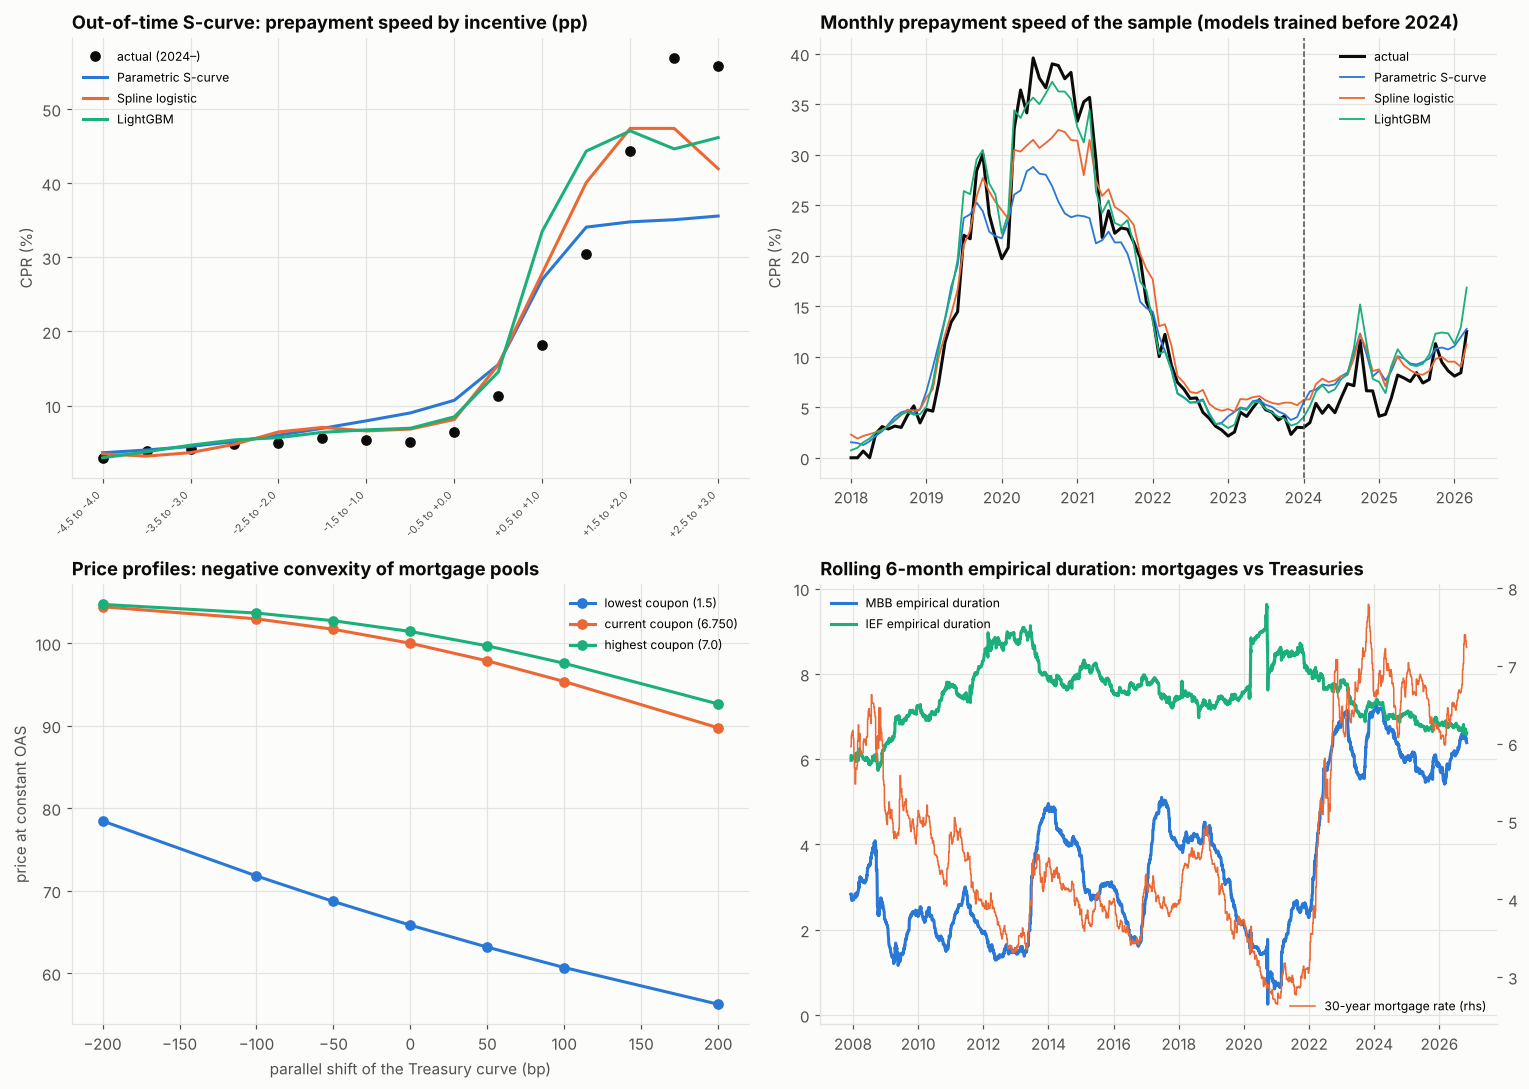

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
st = SCURVE["test"]
xs_ = np.arange(len(st))
a.plot(xs_, st["actual"] * 100, "o", color=INK, label="actual (2024–)")
for i, m in enumerate(MODEL_NAMES):
    a.plot(xs_, st[m] * 100, color=PALETTE[i], label=m)
a.set_xticks(xs_[::2], st.index[::2], rotation=45, ha="right", fontsize=7)
a.set_ylabel("CPR (%)")
a.set_title("Out-of-time S-curve: prepayment speed by incentive (pp)")
a.legend(fontsize=8)
a = ax[0, 1]
a.plot(CPR_M.index, CPR_M["actual"] * 100, color=INK, label="actual")
for i, m in enumerate(MODEL_NAMES):
    a.plot(CPR_M.index, CPR_M[m] * 100, color=PALETTE[i], lw=1.2, label=m)
a.axvline(OOT_START, color=INK_2, ls="--", lw=1)
a.set_ylabel("CPR (%)")
a.set_title(
    "Monthly prepayment speed of the sample (models trained before 2024)"
)
a.legend(fontsize=8)
a = ax[1, 0]
xsh = [float(c.split()[0]) for c in PROFILE.columns]
for i, (k, r_) in enumerate(PROFILE.iterrows()):
    a.plot(xsh, r_.values, "o-", color=PALETTE[i], label=k)
a.set_xlabel("parallel shift of the Treasury curve (bp)")
a.set_ylabel("price at constant OAS")
a.set_title("Price profiles: negative convexity of mortgage pools")
a.legend(fontsize=8)
a = ax[1, 1]
a.plot(EMP.index, EMP["MBB"], color=PALETTE[0], label="MBB empirical duration")
a.plot(EMP.index, EMP["IEF"], color=PALETTE[2], label="IEF empirical duration")
a2 = a.twinx()
a2.plot(
    EMP.index,
    EMP["30-year mortgage rate"],
    color=PALETTE[1],
    lw=1,
    label="30-year mortgage rate (rhs)",
)
a2.grid(False)
a.set_title("Rolling 6-month empirical duration: mortgages vs Treasuries")
a.legend(loc="upper left", fontsize=8)
a2.legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_fig(fig, "01_mbs_oas")
plt.show()

In [14]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Effective duration by coupon and prepayment model",
        "Option cost by coupon (bp)",
    ),
)
for i, m in enumerate(MODEL_NAMES):
    a_ = ANALYTICS[ANALYTICS["prepayment model"] == m]
    dash.add_trace(
        go.Bar(
            x=a_["pool"],
            y=a_["effective duration"],
            name=m,
            marker_color=PALETTE[i],
        ),
        1,
        1,
    )
    dash.add_trace(
        go.Bar(
            x=a_["pool"],
            y=a_["option cost (bp)"],
            name=m,
            marker_color=PALETTE[i],
            showlegend=False,
        ),
        1,
        2,
    )
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Agency mortgage pools: duration and option cost at the"
        " current-coupon OAS"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

*Seeds are fixed. The Treasury curve, the mortgage rate, MOVE and the ETF prices are those of the run date, so prices, spreads and durations move with the market.*

**The data cover a full rate cycle.** The 72,000 loans contribute 2.94 million loan-months and 30,560 full prepayments.
- **Annual speeds:** the sample's prepayment speed rose from 17% CPR in 2019 to 34% in 2020 and 25% in 2021, when mortgage rates fell below 3%. It then collapsed to 4% in 2023 as rates passed 7%, and recovered to 8% in 2025.
- **By vintage:** 80% of the 2018 loans have been repaid, but only 19% of the 2021 loans, which carry 3% coupons and are locked in.

**Prepayment models out of time (2024 to March 2026).**

| Model | Log loss | AUC | Mean CPR (actual 7.1%) | MAE of monthly CPR, train | MAE of monthly CPR, test |
|---|---|---|---|---|---|
| LightGBM | 0.0359 | 0.676 | 9.5% | 1.4 pts | 2.4 pts |
| Parametric S-curve | 0.0362 | 0.658 | 9.2% | 3.2 pts | 2.2 pts |
| Spline logistic | 0.0367 | 0.629 | 8.8% | 2.4 pts | 1.9 pts |
| Constant | 0.0397 | 0.500 | — | — | — |

- **Loan-level ranking:** LightGBM ranks loans best and tracks the training years most closely; its incentive alone accounts for 61% of the gain, followed by loan age (14%) and loan size (10%).
- **Overprediction out of time:** all three models overstate speeds after 2023 by 2–2.5 CPR points. The miss is concentrated near the money: loans 0.5–1.0 points in the money prepaid at 18% CPR, against 27–34% predicted. Borrowers refinanced less eagerly at a given incentive than in 2019–2021, when the whole industry was geared to refinancing.
- **Deep lock-in:** far out of the money (incentive below −3 points), all three are within a point of the actual 3–5% CPR.
- **Parametric S-curve:** each parameter has a reading:
  - turnover of 11.5% a year, damped by 25% per point out of the money;
  - refinancing up to 33% CPR on top, with a mid-point at 0.6 points of incentive and a width of 0.2 points;
  - a 12-month seasoning ramp and a June peak.

**Rate model.**
- **Market inputs:** the 2-year Treasury yield is 4.61%, the 10-year 4.95%, and the 30-year mortgage rate 7.24% (2.29 points over the 10-year).
- **Volatility:** the MOVE index of 94 basis points a year gives a Hull–White σ of 110 bp with 3% mean reversion. The realised volatility of the 10-year yield over the last year was lower, at 70 bp.
- **Mortgage rate:** it moves 0.77 for each point of the 10-year yield.
- **Fit to the curve:** the simulated paths reprice the Treasury curve exactly and reproduce the 10-year par yield to the basis point.

**The pools.** The 40,049 outstanding loans (\$10.6 billion) fall into 12 coupons from 1.5% to 7.0%.
- **Out of the money:** half the balance is in coupons of 3% or less. The balance-weighted incentive is −2.7 points, and two-thirds of the balance is more than 2 points out of the money.
- **Current coupon:** a new pool at 7.25% note rate and 6.75% coupon prices at par with an OAS of 105 bp under LightGBM. Its Z-spread is 178 bp, so the borrowers' option costs the investor 73 bp a year. Its effective duration is 3.8 and its convexity −177.

| Coupon (LightGBM, at the current-coupon OAS) | Price | CPR, year 1 | WAL (years) | Option cost (bp) | Duration | Convexity |
|---|---|---|---|---|---|---|
| 2.0 | 70.3 | 2.8% | 10.8 | −9 | 8.3 | +113 |
| 3.0 | 78.0 | 3.9% | 10.3 | +7 | 8.0 | +46 |
| 4.0 | 85.0 | 4.8% | 10.0 | +18 | 7.3 | +3 |
| 5.0 | 91.2 | 6.2% | 9.5 | +29 | 6.4 | −45 |
| 6.0 | 97.2 | 9.4% | 7.3 | +47 | 4.7 | −129 |
| 7.0 | 101.4 | 17.8% | 5.5 | +73 | 3.0 | −176 |

- **Discount pools:** the low coupons behave almost like long bonds, with durations above 8 and positive convexity. Their option is so far out of the money that it costs nothing; faster turnover when rates fall even works in the investor's favour, which shows up as a small negative option cost.
- **Premium pools:** duration falls and negative convexity deepens with the coupon.
- **Price profiles:** a 200 bp fall in rates lifts the 1.5% pool by 19% but the current coupon by only 4.4%. A 200 bp rise takes 14.6% and 10.2% off them.

**Model risk is larger than rate-model risk.**
- **Prepayment model:**
  - for the current coupon, the three models give OAS of 105–120 bp, option costs of 56–73 bp and durations of 3.8–4.5;
  - for the outstanding pools, the parametric S-curve and LightGBM agree (balance-weighted duration 7.1 and 7.0), but the spline logistic gives 4.6 and values the pools 4 points higher. It projects 4–8% CPR for the deep-discount pools instead of 2–5%: it combines deep negative incentives with long seasoning differently, in a region with few observations.
- **Rate model:**
  - cutting σ by 25% raises the current coupon's OAS from 105 to 133 bp, and raising it by 25% lowers the OAS to 75 bp;
  - mean reversion between 1% and 10% (each recalibrated to MOVE) moves the OAS by 14 bp;
  - duration stays between 3.6 and 4.1 in all these cases.

**The market agrees on the sign.**
- **MBB:** the empirical duration of the agency mortgage ETF has ranged from almost zero to 7.3 since 2008 (standard deviation 1.8), rising with mortgage rates (correlation +0.77). It is 6.4 today, close to the 7.0–7.1 of the parametric and LightGBM models.
- **IEF:** the Treasury ETF's duration moves in the opposite direction (correlation −0.71) and much less (standard deviation 0.7).

**What this means for MBS valuation and risk.**
- **Today's universe:** most agency loans are deep out of the money, so mortgage portfolios now carry long, bond-like durations and little negative convexity. That reverses quickly for new production and would reverse for the whole universe after a large fall in rates.
- **Volatility:** OAS depends on the volatility assumption as much as on the spread the market pays, so OAS comparisons are only meaningful under one volatility setting.
- **Prepayment model:** the far left tail of the S-curve (lock-in) drives the durations of today's book. A model can track aggregate speeds well and still misprice that tail, so validation should look at speeds by incentive bucket and at the durations implied, not only at loan-level accuracy.
- **Machine learning:** gradient boosting with monotonic constraints ranks loans best and is safe to use on simulated paths. It still inherits the refinancing behaviour of 2020–2021 and overstated speeds near the money afterwards, so a recent recalibration window matters.

**Limitations.**
- **Market price:** pool prices are not public, so the OAS is anchored on a current-coupon pool assumed at par. Other pools are priced at that OAS rather than solved from market prices. A single 0.5% fee separates note rates from coupons, and payment delays and the guarantor's buyouts of delinquent loans are ignored.
- **Models:** Hull–White is a one-factor model fitted to Treasuries and MOVE, not to swaptions, and the mortgage rate is a fixed linear function of the 10-year yield. The prepayment data cover only the 2018–2023 vintages of one agency, full payoffs only (no curtailments), with ages capped at six years.

In [15]:
SUMMARY.to_csv(OUT_DIR / "sample_by_vintage.csv")
PREPAY_CMP.to_csv(OUT_DIR / "prepayment_model_comparison.csv")
THETA.to_csv(OUT_DIR / "s_curve_parameters.csv")
SCURVE.to_csv(OUT_DIR / "cpr_by_incentive.csv")
CPR_M.to_csv(OUT_DIR / "monthly_cpr_actual_vs_model.csv")
IMP.to_csv(OUT_DIR / "lightgbm_feature_importance.csv")
CAL.to_csv(OUT_DIR / "hull_white_calibration.csv")
ZERO_TABLE.to_csv(OUT_DIR / "treasury_zero_curve.csv")
POOL_TABLE.to_csv(OUT_DIR / "pools.csv")
ANALYTICS.to_csv(OUT_DIR / "pool_analytics.csv", index=False)
MODEL_RISK.to_csv(OUT_DIR / "prepayment_model_risk.csv")
VOL_SENS.to_csv(OUT_DIR / "rate_model_sensitivity.csv")
PROFILE.to_csv(OUT_DIR / "price_profiles.csv")
EMP_SUM.to_csv(OUT_DIR / "empirical_duration_summary.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_mbs_oas.png, cpr_by_incentive.csv, dashboard.html, dashboard.png, empirical_duration_summary.csv, hull_white_calibration.csv, lightgbm_feature_importance.csv, monthly_cpr_actual_vs_model.csv, pool_analytics.csv, pools.csv, prepayment_model_comparison.csv, prepayment_model_risk.csv, price_profiles.csv, rate_model_sensitivity.csv, s_curve_parameters.csv, sample_by_vintage.csv, treasury_zero_curve.csv


## References

- Boudoukh, J., Whitelaw, R. F., Richardson, M., & Stanton, R. (1997). Pricing mortgage-backed securities in a multifactor interest rate environment: A multivariate density estimation approach. *Review of Financial Studies*, 10(2), 405–446. https://doi.org/10.1093/rfs/10.2.405
- Brigo, D., & Mercurio, F. (2006). *Interest rate models: Theory and practice* (2nd ed.). Springer.
- Fabozzi, F. J. (Ed.). (2016). *The handbook of mortgage-backed securities* (7th ed.). Oxford University Press.
- Freddie Mac. (2026). *Single-Family Loan-Level Dataset* [Data set]. https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *Review of Financial Studies*, 3(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Richard, S. F., & Roll, R. (1989). Prepayments on fixed-rate mortgage-backed securities. *Journal of Portfolio Management*, 15(3), 73–82. https://doi.org/10.3905/jpm.1989.409207
- Sadhwani, A., Giesecke, K., & Sirignano, J. (2021). Deep learning for mortgage risk. *Journal of Financial Econometrics*, 19(2), 313–368. https://doi.org/10.1093/jjfinec/nbaa025
- Schwartz, E. S., & Torous, W. N. (1989). Prepayment and the valuation of mortgage-backed securities. *Journal of Finance*, 44(2), 375–392. https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Stanton, R. (1995). Rational prepayment and the valuation of mortgage-backed securities. *Review of Financial Studies*, 8(3), 677–708. https://doi.org/10.1093/rfs/8.3.677